In [2]:
import matplotlib.pyplot as plt
import cv2
from ultralytics import YOLO
from deepface import DeepFace
from retinaface import RetinaFace

In [3]:
yolo = YOLO("yolo11n.pt")

In [4]:
test_image = "./../img/test_images/RDJ_CH_XX.jpg"


image 1/1 d:\Studies\AI Models_Applications\FINAL\Person_Detection_and_Face_Recongnition\src\..\img\test_images\RDJ_CH_XX.jpg: 448x640 3 persons, 121.1ms
Speed: 5.5ms preprocess, 121.1ms inference, 2.0ms postprocess per image at shape (1, 3, 448, 640)


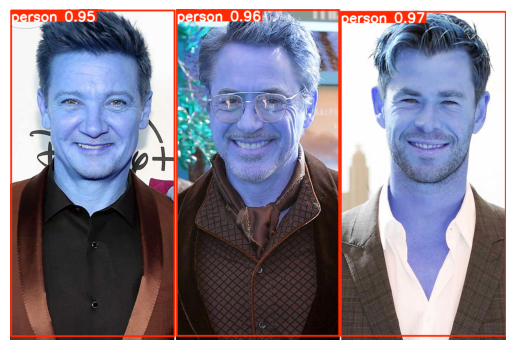

In [5]:
results = yolo(test_image, classes=[0])
results[0].plot()
plt.imshow(results[0].plot())
plt.axis('off')
plt.show()

0.93


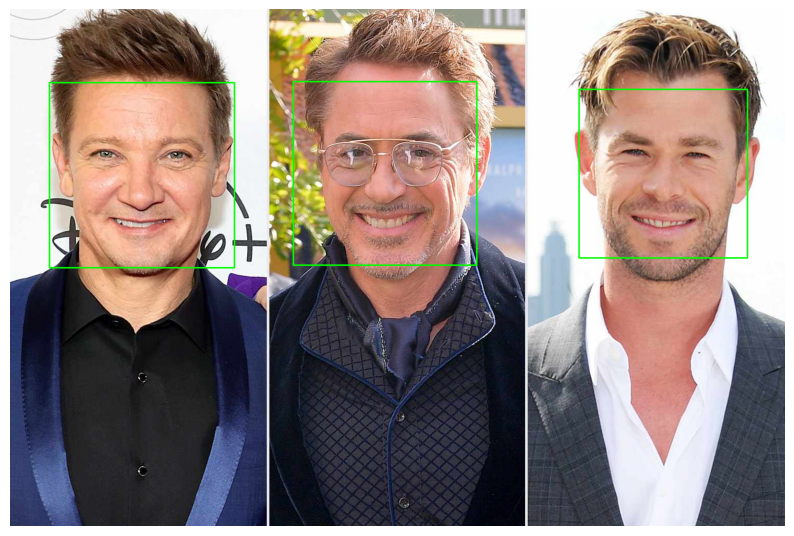

In [ ]:
faces = []
crop_img = [cv2.cvtColor(cv2.imread(test_image), cv2.COLOR_BGR2RGB)]

for img in crop_img:
  try:
    extracted_face = DeepFace.extract_faces(img, detector_backend='retinaface')
    print(extracted_face[0]["confidence"])
    img_with_boxes = img.copy()

    for face_info in extracted_face:
      if(face_info['confidence'] > 0.85):
        facial_area = face_info['facial_area']
        x, y, w, h = facial_area['x'], facial_area['y'], facial_area['w'], facial_area['h']
        faces.append(img[int(facial_area['y']):int(facial_area['y']+facial_area['h']), int(facial_area['x']):int(facial_area['x']+facial_area['w'])])

        cv2.rectangle(img_with_boxes, (x, y), (x + w, y + h), (0, 255, 0), 2) # Green box

    plt.figure(figsize=(10, 10))
    plt.imshow(img_with_boxes)
    plt.axis('off')
    plt.show()
  except:
    pass

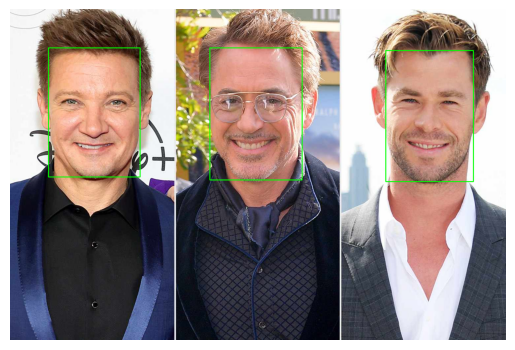

In [7]:
faces = []
img = cv2.cvtColor(cv2.imread(test_image), cv2.COLOR_BGR2RGB)
try:
  detections = RetinaFace.detect_faces(test_image)
  img_with_boxes = img.copy()
  if isinstance(detections, dict):
    for key, face in detections.items():
      conf = face.get('score', face.get('confidence', 1.0))
      if conf >= 0.85:
        fa = face.get('facial_area', None)
        if isinstance(fa, dict):
          if all(k in fa for k in ('x','y','w','h')):
            x, y, w, h = fa['x'], fa['y'], fa['w'], fa['h']
          elif all(k in fa for k in ('x1','y1','x2','y2')):
            x, y, x2, y2 = fa['x1'], fa['y1'], fa['x2'], fa['y2']
            w, h = x2 - x, y2 - y
        elif isinstance(fa, (list, tuple)) and len(fa) == 4:
          x, y, x2, y2 = fa
          w, h = x2 - x, y2 - y
        x, y, w, h = int(x), int(y), int(w), int(h)
        faces.append(img[y:y+h, x:x+w])
        cv2.rectangle(img_with_boxes, (x, y), (x + w, y + h), (0, 255, 0), 2)  # Green box

  plt.imshow(img_with_boxes)
  plt.axis('off')
  plt.show()
except:
  pass

In [ ]:
for face in faces:
  try:
    db_path = "./../img/data/test"
    models = ["VGG-Face", "Facenet", "Facenet512", "DeepFace", "ArcFace"]
    backends = ['opencv','retinaface','yolov11n']
    metrics = ["cosine", "euclidean", "euclidean_l2", "angular"]

    results = DeepFace.find(face,
                            db_path=db_path,
                            model_name=models[0],
                            detector_backend=backends[1],
                            distance_metric=metrics[0],
                            enforce_detection=False
                            )
    name = results[0]["identity"].iloc[0].split('/')[-2].replace("pins_", "")
    confidence = results[0]["confidence"].iloc[0]

    plt.title(f"{name} : {confidence:.2f}%")
    plt.imshow(face)
    plt.axis('off')
    plt.show()

  except:
    pass

26-01-25 18:51:41 - Found 3555 newly added image(s), 0 removed image(s), 0 replaced image(s).


Finding representations:  45%|████▍     | 1590/3555 [59:18<1:24:13,  2.57s/it]